# Лабораторная работа №2 — Задача классификации на данных о пассажирах «Титаника»

**Источник данных:** Kaggle, Titanic Dataset (yasserh), файл `Titanic-Dataset.csv`.
**Цель:** по характеристикам пассажира предсказать, выжил он (`Survived = 1`) или погиб (`Survived = 0`).
**Главная метрика:** F1 по классу «выжил»; минимально допустимое значение — 0.70. Для полноты считаются Accuracy, Precision и Recall.

**Структура работы:** разведочный анализ → подготовка данных и разбиение → baseline → пять алгоритмов → сводное сравнение → важность признаков → разбор ошибок лучшей модели.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid", palette="deep")

SEED = 42
MIN_F1 = 0.70

## 1. Разведочный анализ данных (EDA)

In [2]:
candidates_paths = ["Titanic-Dataset.csv", "data/Titanic-Dataset.csv", "/kaggle/input/titanic-dataset/Titanic-Dataset.csv"]
csv_path = next((p for p in candidates_paths if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError("Файл Titanic-Dataset.csv не найден: положите его рядом с ноутбуком")

df = pd.read_csv(csv_path)
print("строк и столбцов:", df.shape)
print("полные дубликаты:", df.duplicated().sum())
print("дубликаты без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
df.head()

строк и столбцов: (891, 12)
полные дубликаты: 0
дубликаты без PassengerId: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "NaN, шт.": df.isna().sum(),
    "NaN, %": (df.isna().mean() * 100).round(1),
    "уникальных значений": df.nunique(),
})
overview

,dtype,"NaN, шт.","NaN, %",уникальных значений
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,object,0,0.0,891
Sex,object,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,object,0,0.0,681
Fare,float64,0,0.0,248


**Первые наблюдения**
- В таблице 891 пассажир и 12 столбцов; повторяющихся строк нет.
- Числовые признаки — `Age`, `Fare`, `SibSp`, `Parch`; категориальные — `Sex`, `Embarked`; `Pclass` (класс каюты 1–3) имеет естественный порядок.
- **Пропуски:** `Age` — 177 значений (19.9%), `Cabin` — 687 (77.1%), `Embarked` — 2.
- **Признаки-идентификаторы:** `PassengerId` и `Name` различаются у каждого человека, у `Ticket` 681 уникальное значение на 891 строку, а `Cabin` — это номер каюты с огромной долей пропусков. По таким столбцам алгоритм может «опознать» конкретного пассажира, вместо того чтобы искать общие закономерности.

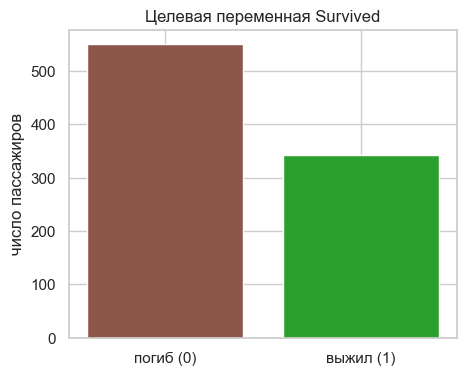

{0: 549, 1: 342}
доля выживших: 0.384


In [4]:
class_counts = df["Survived"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["погиб (0)", "выжил (1)"], class_counts.values, color=["#8c564b", "#2ca02c"])
ax.set_ylabel("число пассажиров")
ax.set_title("Целевая переменная Survived")
plt.show()

print(class_counts.to_dict())
print("доля выживших:", round(df["Survived"].mean(), 3))

- Выжили 38.4% пассажиров, погибли 61.6% — выборка заметно несбалансирована. Тривиальный ответ «погиб для всех» уже даёт Accuracy около 0.62, поэтому ориентироваться только на Accuracy нельзя — выбрана метрика F1. По той же причине разбиение на train/test нужно делать со стратификацией.

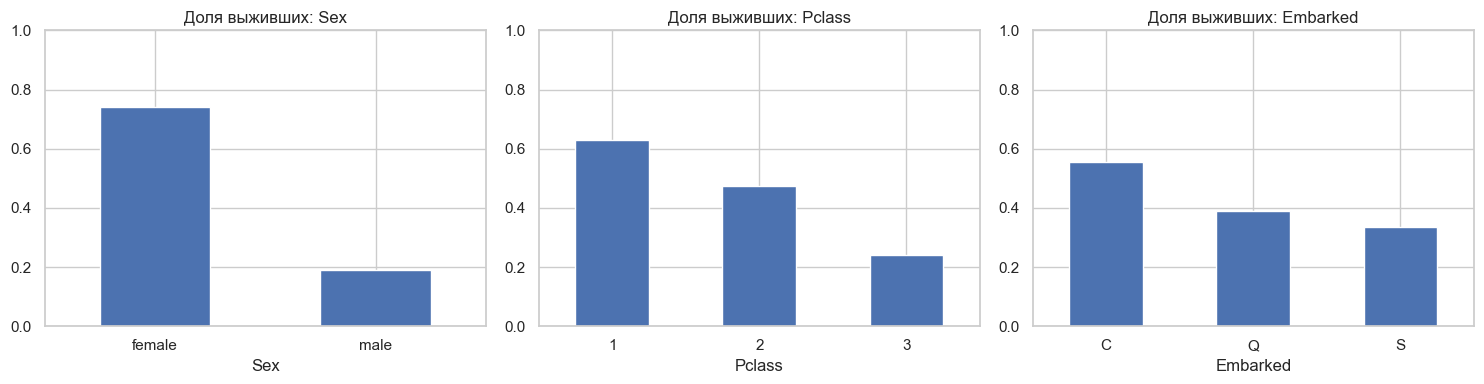

Sex {'female': 0.742, 'male': 0.189}
Pclass {1: 0.63, 2: 0.473, 3: 0.242}
Embarked {'C': 0.554, 'Q': 0.39, 'S': 0.337}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    df.groupby(col)["Survived"].mean().plot(kind="bar", ax=ax, color="#4c72b0")
    ax.set_title(f"Доля выживших: {col}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

for col in ["Sex", "Pclass", "Embarked"]:
    print(col, df.groupby(col)["Survived"].mean().round(3).to_dict())

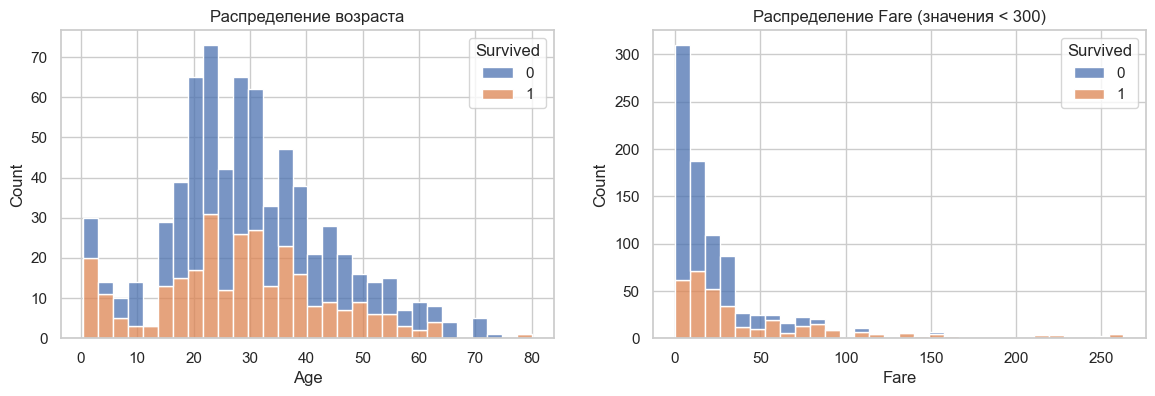

Age
(0, 12]      0.580
(12, 18]     0.429
(18, 40]     0.388
(40, 60]     0.391
(60, 100]    0.227
Name: Survived, dtype: float64
корреляция Fare и Pclass: -0.55


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[0])
axes[0].set_title("Распределение возраста")
sns.histplot(data=df[df["Fare"] < 300], x="Fare", hue="Survived", bins=30, multiple="stack", ax=axes[1])
axes[1].set_title("Распределение Fare (значения < 300)")
plt.show()

print(df.groupby(pd.cut(df["Age"], [0, 12, 18, 40, 60, 100]), observed=True)["Survived"].mean().round(3))
print("корреляция Fare и Pclass:", round(df["Fare"].corr(df["Pclass"]), 2))

**Что показывают графики**
- **Пол** — главный фактор: выжили 74% женщин и лишь 19% мужчин (в соответствии с правилом «женщины и дети — первыми»).
- **Класс каюты:** 63% выживших в 1-м классе, 47% во 2-м и 24% в 3-м.
- **Возраст:** у детей младше 12 лет шансы выше (≈58%), у пассажиров старше 60 — ниже (≈23%).
- **Fare** растёт вместе с выживаемостью, но во многом это эффект класса (корреляция с `Pclass` порядка −0.55). Распределение стоимости билета резко скошено вправо (максимум 512).
- Для порта `C` выживаемость выше (55%), вероятно, из-за большей доли пассажиров 1-го класса.

### Извлечение обращения из имени
Полное имя уникально и для модели бесполезно, но в нём есть обращение (`Mr`, `Mrs`, `Miss`, `Master` и др.) — оно отражает пол, примерный возраст (`Master` — мальчик) и семейное положение. Создадим из него категориальный признак `Title`; редкие обращения сведём в группу `Rare`.

In [7]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]
print(df["Title"].value_counts().to_dict())

df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
df.groupby("Title")["Survived"].agg(["count", "mean"]).round(3)

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Col': 2, 'Mlle': 2, 'Major': 2, 'Ms': 1, 'Mme': 1, 'Don': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}


,count,mean
Title,,
Master,40,0.575
Miss,185,0.703
Mr,517,0.157
Mrs,126,0.794
Rare,23,0.348


- Среди `Mr` выжили около 16%, среди `Mrs` и `Miss` — 70–79%, среди `Master` (мальчиков) — около 57%. Итоговых категорий всего пять, поэтому конкретного человека по ним определить нельзя.

### Эксперимент: что будет, если оставить идентификатор

In [8]:
# временное разбиение — только для этого эксперимента
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(df[["PassengerId"]], df["Survived"], test_size=0.2,
                                              random_state=SEED, stratify=df["Survived"])
tree_on_id = DecisionTreeClassifier(random_state=SEED).fit(Xi_tr, yi_tr)
print("Дерево на одном PassengerId -> F1 на train:", round(f1_score(yi_tr, tree_on_id.predict(Xi_tr)), 3),
      "| F1 на test:", round(f1_score(yi_te, tree_on_id.predict(Xi_te)), 3))

Дерево на одном PassengerId -> F1 на train: 1.0 | F1 на test: 0.403


- На обучающей части F1 равен 1.0, на тестовой — около 0.4. Дерево попросту выучило номера пассажиров и не нашло никакой закономерности, поэтому `PassengerId`, `Name`, `Ticket` и `Cabin` исключаются из признаков.
- Утечки целевой переменной в данных нет: все оставшиеся признаки известны ещё до катастрофы.
- **Краткий итог EDA:** выживаемость определяют прежде всего пол/обращение, класс и возраст; идентификаторы приводят к запоминанию; из-за дисбаланса классов используем стратификацию и F1.

## 2. Подготовка данных

In [9]:
NUM_COLS = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
CAT_COLS = ["Sex", "Embarked", "Title"]
ALL_COLS = NUM_COLS + CAT_COLS

X = df[ALL_COLS]
y = df["Survived"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("train:", X_tr.shape, "| test:", X_te.shape)
print("доля выживших: train", round(y_tr.mean(), 3), "| test", round(y_te.mean(), 3))

train: (712, 8) | test: (179, 8)
доля выживших: train 0.383 | test 0.385


- Данные делятся в пропорции 80/20 со стратификацией по `Survived` и фиксированным `random_state=42`. Все модели используют одни и те же `X_tr` / `X_te`.
- Тест применяется исключительно для итоговой оценки. Гиперпараметры подбираются и лучшая модель выбирается по 5-кратной кросс-валидации на обучающей части.

In [10]:
def build_pipe(estimator, scaled):
    """Предобработка + модель в одном Pipeline (все статистики считаются только по train)"""
    num_part = [("fill", SimpleImputer(strategy="median"))]
    if scaled:
        num_part.append(("scale", StandardScaler()))
    cat_part = [("fill", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]
    prep = ColumnTransformer([("num", Pipeline(num_part), NUM_COLS),
                              ("cat", Pipeline(cat_part), CAT_COLS)])
    return Pipeline([("prep", prep), ("model", estimator)])

demo = build_pipe(DummyClassifier(), scaled=False).fit(X_tr, y_tr)
print(list(demo.named_steps["prep"].get_feature_names_out()))

['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Rare']


**Как обработаны признаки**
- `Age`: пропуски заменяются **медианой** — терять пятую часть строк нежелательно, а медиана не чувствительна к выбросам.
- `Embarked`: два пропуска заполняются **наиболее частой категорией**.
- `Sex`, `Embarked`, `Title`: **One-Hot-кодирование**, так как категории не упорядочены, а числовые коды 0/1/2 навязали бы модели несуществующий порядок.
- `Pclass` остаётся числовым, поскольку классы упорядочены.
- Вся обработка встроена в `Pipeline`: медиана, мода, список категорий и параметры масштабирования вычисляются только на обучающих данных (внутри кросс-валидации — только на обучающих фолдах), а к тесту лишь применяются. Это исключает утечку информации.

**Где нужно масштабирование**
- **Decision Tree, Random Forest, Gradient Boosting — не требуется:** деревья сравнивают признак с порогом, и растяжение шкалы не меняет порядок объектов, а значит и разбиения.
- **SVM и KNN — требуется:** обе модели опираются на расстояния между объектами. Без масштабирования `Fare` (до 512) перекроет бинарные признаки и `Pclass`. Поэтому для них добавлен `StandardScaler`.

## 3. Метрики качества

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def calc_metrics(y_true, y_hat):
    return {"Accuracy": accuracy_score(y_true, y_hat),
            "Precision": precision_score(y_true, y_hat, zero_division=0),
            "Recall": recall_score(y_true, y_hat, zero_division=0),
            "F1": f1_score(y_true, y_hat, zero_division=0)}

scores = {}    # метрики на test
fitted = {}    # обученные модели

def report(name, model, cv_f1=np.nan):
    """Считает метрики на train/test, рисует confusion matrix для test"""
    pred_te = model.predict(X_te)
    table = pd.DataFrame({"train": calc_metrics(y_tr, model.predict(X_tr)),
                          "test": calc_metrics(y_te, pred_te)})
    scores[name] = {**table["test"], "CV F1": cv_f1}
    fitted[name] = model

    cm = confusion_matrix(y_te, pred_te)
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Greens", colorbar=False)
    plt.title(f"{name}: confusion matrix на test")
    plt.grid(False)
    plt.show()
    return table.round(4)

Положительным классом считается «выжил».
- **Accuracy** — доля правильных ответов среди всех.
- **Precision** = TP / (TP + FP): какая часть пассажиров, названных выжившими, на самом деле выжила.
- **Recall** = TP / (TP + FN): какую часть настоящих выживших удалось обнаружить.
- **F1** — среднее гармоническое Precision и Recall. Оно велико только при одновременно высоких обеих метриках, поэтому при дисбалансе классов информативнее Accuracy.

**Смысл ошибок в этой задаче**
- **False Positive (FP):** модель предсказала «выжил», пассажир погиб — шансы на спасение завышены.
- **False Negative (FN):** модель предсказала «погиб», пассажир выжил — выживший остался незамеченным.

## 4. Baseline: Dummy-классификатор

TN=110  FP=0  FN=69  TP=0


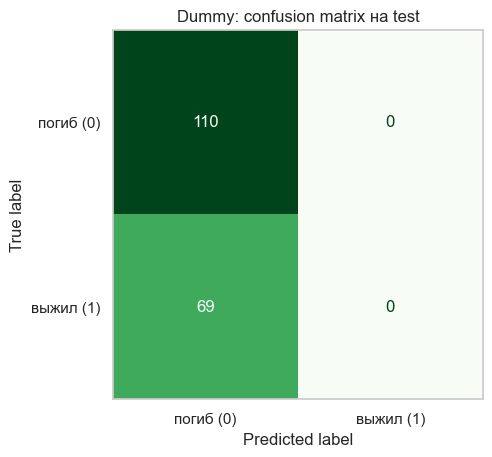

,train,test
Accuracy,0.6166,0.6145
Precision,0.0000,0.0000
Recall,0.0000,0.0000
F1,0.0000,0.0000


In [12]:
dummy = build_pipe(DummyClassifier(strategy="most_frequent"), scaled=False).fit(X_tr, y_tr)
report("Dummy", dummy)

- Dummy в любом случае отвечает «погиб». Его Accuracy (≈ 0.61) равна доле погибших в тесте, а Precision, Recall и F1 нулевые: ни один выживший не найден (TP = 0, FN = 69).
- Следовательно, содержательная модель должна заметно обгонять этот уровень, прежде всего по F1.

## 5. Обучение и настройка моделей

### 5.1 Decision Tree
Сначала обучим дерево без ограничений, чтобы оценить склонность к переобучению. Сравнение выполняется по кросс-валидации на train, тест не используется.

In [13]:
tree_free = build_pipe(DecisionTreeClassifier(random_state=SEED), scaled=False)
cv_free = cross_validate(tree_free, X_tr, y_tr, cv=skf, scoring="f1", return_train_score=True)
print("глубина дерева без ограничений:", tree_free.fit(X_tr, y_tr).named_steps["model"].get_depth())
print("F1 на обучающих фолдах:", round(cv_free["train_score"].mean(), 4),
      "| F1 на валидационных фолдах:", round(cv_free["test_score"].mean(), 4))

глубина дерева без ограничений: 18
F1 на обучающих фолдах: 0.9786 | F1 на валидационных фолдах: 0.6961


оптимальные параметры: {'model__max_depth': 6, 'model__min_samples_leaf': 10}
F1 по кросс-валидации: 0.7338
TN=99  FP=11  FN=23  TP=46


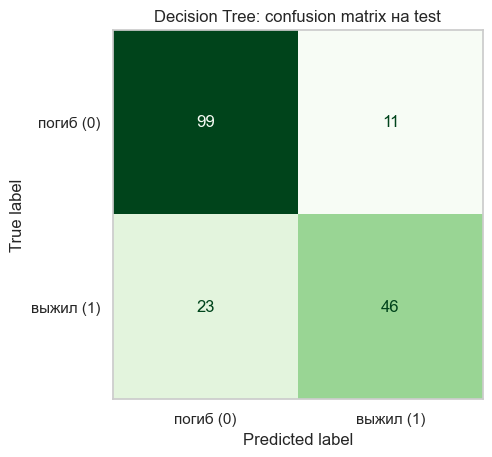

,train,test
Accuracy,0.8567,0.8101
Precision,0.8638,0.8070
Recall,0.7436,0.6667
F1,0.7992,0.7302


In [14]:
gs_dt = GridSearchCV(
    build_pipe(DecisionTreeClassifier(random_state=SEED), scaled=False),
    param_grid={"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]},
    cv=skf, scoring="f1", n_jobs=-1
)
gs_dt.fit(X_tr, y_tr)
print("оптимальные параметры:", gs_dt.best_params_)
print("F1 по кросс-валидации:", round(gs_dt.best_score_, 4))

tree = gs_dt.best_estimator_
report("Decision Tree", tree, gs_dt.best_score_)

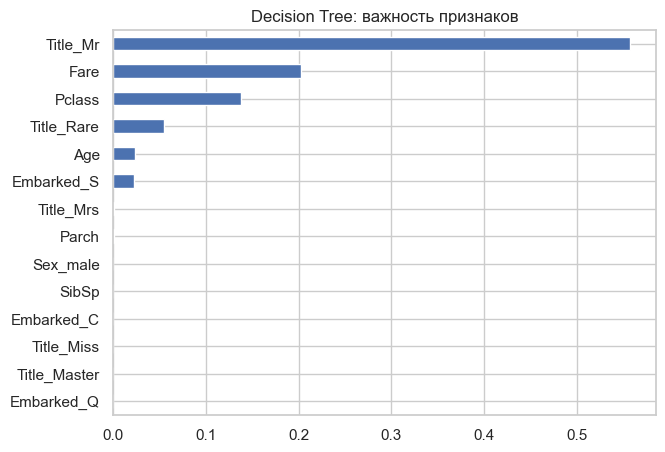

Title_Mr        0.557
Fare            0.203
Pclass          0.138
Title_Rare      0.054
Age             0.024
Embarked_S      0.022
Title_Mrs       0.001
Parch           0.001
Sex_male        0.000
SibSp           0.000
Title_Master    0.000
Embarked_Q      0.000
Embarked_C      0.000
Title_Miss      0.000
dtype: float64

In [15]:
def feature_importances(pipe):
    cols = [n.split("__")[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    return pd.Series(pipe.named_steps["model"].feature_importances_, index=cols).sort_values(ascending=False)

fi_tree = feature_importances(tree)
fi_tree.sort_values().plot(kind="barh", figsize=(7, 5), color="#4c72b0", title="Decision Tree: важность признаков")
plt.show()
fi_tree.round(3)

- **Переобучение.** Дерево без ограничений доходит до глубины 18: на обучающих фолдах F1 около 0.98 (практически запоминание), на валидационных — лишь около 0.70. Это типичный признак переобучения.
- **Дерево с подобранными параметрами** (`max_depth=6`, `min_samples_leaf=10`) показывает F1 = 0.730 на тесте — **порог пройден**. От train к test F1 снижается с 0.799 до 0.730, Accuracy — с 0.857 до 0.810: небольшое переобучение остаётся, но ограничения глубины и листа удерживают его в умеренных рамках.
- **Типы ошибок.** FN = 23 заметно больше FP = 11: дерево чаще не замечает выживших (Recall 0.667 при Precision 0.807).
- **Важность признаков.** Больше половины приходится на `Title_Mr` (0.557) — по нему построено первое разбиение «взрослый мужчина / остальные». Далее идут `Fare` (0.203) и `Pclass` (0.138). У `Sex_male` важность нулевая: все `Mr` — мужчины, и после разбиения по `Title_Mr` пол не добавляет информации.

### 5.2 Random Forest

оптимальные параметры: {'model__max_depth': 4, 'model__min_samples_leaf': 1}
F1 по кросс-валидации: 0.763
TN=97  FP=13  FN=22  TP=47


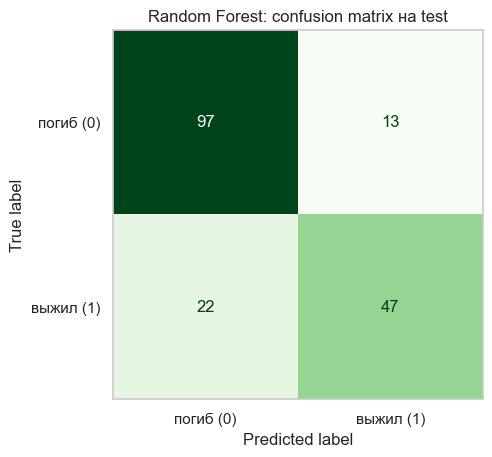

,train,test
Accuracy,0.8413,0.8045
Precision,0.8333,0.7833
Recall,0.7326,0.6812
F1,0.7797,0.7287


In [16]:
gs_rf = GridSearchCV(
    build_pipe(RandomForestClassifier(n_estimators=200, random_state=SEED), scaled=False),
    param_grid={"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5]},
    cv=skf, scoring="f1", n_jobs=-1
)
gs_rf.fit(X_tr, y_tr)
print("оптимальные параметры:", gs_rf.best_params_)
print("F1 по кросс-валидации:", round(gs_rf.best_score_, 4))

forest = gs_rf.best_estimator_
report("Random Forest", forest, gs_rf.best_score_)

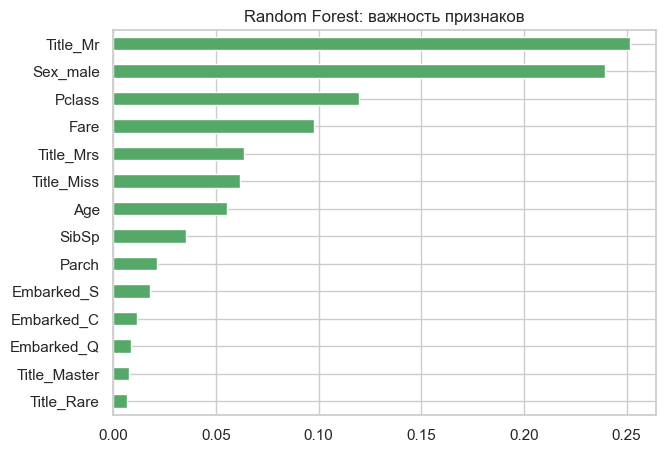

Title_Mr        0.251
Sex_male        0.239
Pclass          0.120
Fare            0.098
Title_Mrs       0.064
Title_Miss      0.062
Age             0.056
SibSp           0.036
Parch           0.021
Embarked_S      0.018
Embarked_C      0.012
Embarked_Q      0.009
Title_Master    0.008
Title_Rare      0.007
dtype: float64

In [17]:
fi_forest = feature_importances(forest)
fi_forest.sort_values().plot(kind="barh", figsize=(7, 5), color="#55a868", title="Random Forest: важность признаков")
plt.show()
fi_forest.round(3)

- F1 на тесте — 0.729, **порог пройден**. Разница между train и test невелика (0.780 → 0.729): усреднение 200 деревьев уменьшает разброс предсказаний. Как и у дерева, FN (22) больше FP (13).
- **В сравнении с Decision Tree** важность распределена ровнее. `Title_Mr` (0.251) и `Sex_male` (0.239) почти равны: в каждом дереве леса в узле доступна лишь случайная часть признаков, и когда `Title_Mr` недоступен, дерево использует `Sex_male`. Затем следуют `Pclass` (0.120) и `Fare` (0.098). Набор лидеров тот же, но лес не обнуляет вклад коррелирующего признака, как это делает одиночное дерево.

### 5.3 Gradient Boosting

оптимальные параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
F1 по кросс-валидации: 0.7632
TN=99  FP=11  FN=21  TP=48


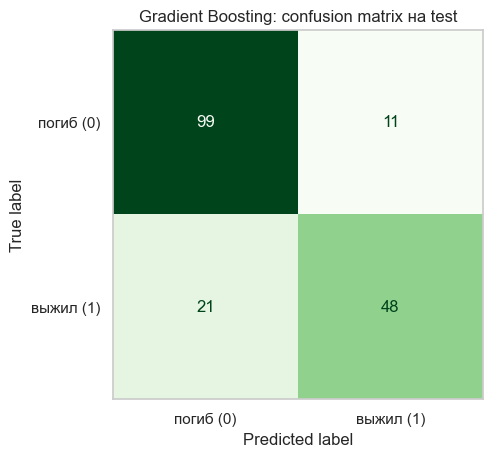

,train,test
Accuracy,0.9368,0.8212
Precision,0.9524,0.8136
Recall,0.8791,0.6957
F1,0.9143,0.7500


In [18]:
gs_gb = GridSearchCV(
    build_pipe(GradientBoostingClassifier(random_state=SEED), scaled=False),
    param_grid={"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]},
    cv=skf, scoring="f1", n_jobs=-1
)
gs_gb.fit(X_tr, y_tr)
print("оптимальные параметры:", gs_gb.best_params_)
print("F1 по кросс-валидации:", round(gs_gb.best_score_, 4))

boost = gs_gb.best_estimator_
report("Gradient Boosting", boost, gs_gb.best_score_)

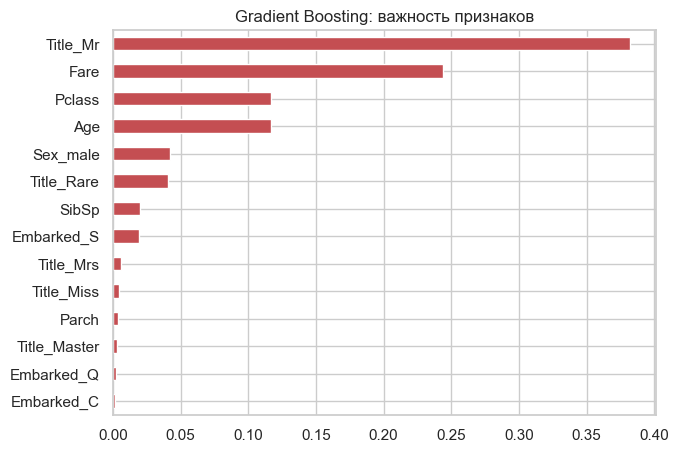

Title_Mr        0.382
Fare            0.244
Pclass          0.117
Age             0.117
Sex_male        0.042
Title_Rare      0.040
SibSp           0.020
Embarked_S      0.019
Title_Mrs       0.006
Title_Miss      0.004
Parch           0.003
Title_Master    0.003
Embarked_Q      0.002
Embarked_C      0.001
dtype: float64

In [19]:
fi_boost = feature_importances(boost)
fi_boost.sort_values().plot(kind="barh", figsize=(7, 5), color="#c44e52", title="Gradient Boosting: важность признаков")
plt.show()
fi_boost.round(3)

- F1 на тесте — 0.750, **порог пройден**; результат лучше, чем у Random Forest (0.729), за счёт и Precision (0.814), и Recall (0.696).
- Зато разрыв между train и test у бустинга самый большой (F1 0.914 → 0.750): деревья строятся последовательно, каждое исправляет ошибки предыдущих на обучающих данных, из-за чего модель сильнее подгоняется под train.
- **В сравнении с Random Forest:** лидер тот же — `Title_Mr` (0.382), однако бустинг заметно активнее использует непрерывные `Fare` (0.244) и `Age` (0.117), а `Sex_male` почти не задействует (0.042), так как тот дублирует `Title_Mr`. При интерпретации стоит помнить, что встроенная важность смещена в пользу признаков с множеством уникальных значений (`Fare`, `Age`).

### 5.4 Support Vector Machine
Проверим, нужен ли SVM масштаб признаков: сравним одну и ту же модель с `StandardScaler` и без него (кросс-валидация на train).

In [20]:
for scaled in [False, True]:
    s = cross_val_score(build_pipe(SVC(random_state=SEED), scaled=scaled), X_tr, y_tr, cv=skf, scoring="f1")
    print("со StandardScaler:    " if scaled else "без масштабирования:  ", "F1 (CV) =", round(s.mean(), 4))

без масштабирования:   F1 (CV) = 0.4443
со StandardScaler:     F1 (CV) = 0.7544


оптимальные параметры: {'model__C': 10, 'model__gamma': 0.03}
F1 по кросс-валидации: 0.7722
TN=99  FP=11  FN=17  TP=52


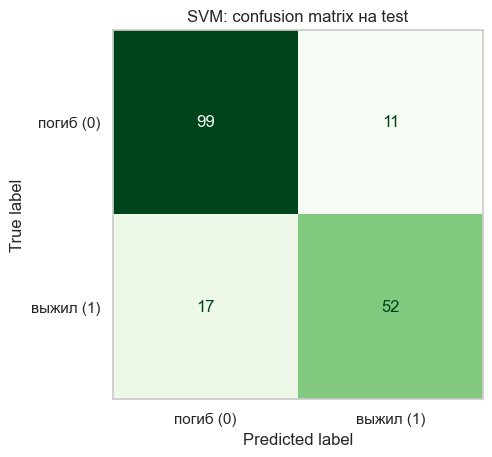

,train,test
Accuracy,0.8385,0.8436
Precision,0.8211,0.8254
Recall,0.7399,0.7536
F1,0.7784,0.7879


In [21]:
gs_svm = GridSearchCV(
    build_pipe(SVC(kernel="rbf", random_state=SEED), scaled=True),
    param_grid={"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.03, 0.1]},
    cv=skf, scoring="f1", n_jobs=-1
)
gs_svm.fit(X_tr, y_tr)
print("оптимальные параметры:", gs_svm.best_params_)
print("F1 по кросс-валидации:", round(gs_svm.best_score_, 4))

svm = gs_svm.best_estimator_
report("SVM", svm, gs_svm.best_score_)

- **Масштабирование необходимо:** без него F1 по CV около 0.44, с ним — около 0.75. SVM строит границу с максимальным зазором, а RBF-ядро `exp(−γ‖x−z‖²)` целиком зависит от расстояний; без стандартизации расстояние определяется почти исключительно `Fare`.
- Лучшая конфигурация (RBF, `C=10`, `gamma=0.03`) даёт **F1 = 0.788 и Accuracy = 0.844**, порог пройден. F1 на train (0.778) и test (0.788) практически одинаковы — признаков переобучения нет.
- Ошибки: FN = 17, FP = 11; Recall (0.754) выше, чем у деревьев.
- Встроенной оценки важности признаков у SVM с RBF-ядром нет.

### 5.5 K-Nearest Neighbors

In [22]:
for scaled in [False, True]:
    s = cross_val_score(build_pipe(KNeighborsClassifier(), scaled=scaled), X_tr, y_tr, cv=skf, scoring="f1")
    print("k=5, со StandardScaler:    " if scaled else "k=5, без масштабирования:  ", "F1 (CV) =", round(s.mean(), 4))

k=5, без масштабирования:   F1 (CV) = 0.6001
k=5, со StandardScaler:     F1 (CV) = 0.7356


оптимальные параметры: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
F1 по кросс-валидации: 0.7469
TN=97  FP=13  FN=17  TP=52


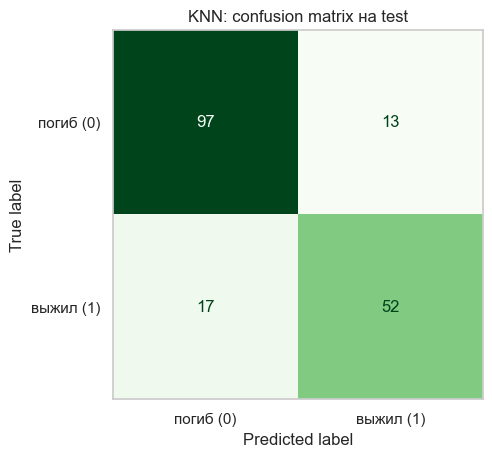

,train,test
Accuracy,0.8806,0.8324
Precision,0.8701,0.8000
Recall,0.8095,0.7536
F1,0.8387,0.7761


In [23]:
gs_knn = GridSearchCV(
    build_pipe(KNeighborsClassifier(), scaled=True),
    param_grid={"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    cv=skf, scoring="f1", n_jobs=-1
)
gs_knn.fit(X_tr, y_tr)
print("оптимальные параметры:", gs_knn.best_params_)
print("F1 по кросс-валидации:", round(gs_knn.best_score_, 4))

knn = gs_knn.best_estimator_
report("KNN", knn, gs_knn.best_score_)

- **Почему для KNN масштаб особенно важен.** Алгоритм не имеет обучаемых параметров: для нового пассажира он находит k ближайших по евклидову расстоянию объектов из train и голосует их метками. Если `Fare` измеряется сотнями, а пол принимает значения 0/1, «ближайшие» пассажиры определяются почти только ценой билета. По CV: без масштабирования F1 ≈ 0.60, со `StandardScaler` ≈ 0.74.
- Лучшая модель (`k=3`) даёт F1 = 0.776 — **порог пройден**. От train к test F1 падает с 0.839 до 0.776: при малом k предсказание сильно зависит от отдельных соседей (на обучающих данных объект — сам себе ближайший сосед).
- Ошибки: FN = 17, FP = 13.

## 6. Сводное сравнение моделей

In [24]:
summary = pd.DataFrame(scores).T
summary["F1 > 0.70"] = np.where(summary["F1"] > MIN_F1, "да", "нет")
summary.round(4)

,Accuracy,Precision,Recall,F1,CV F1,F1 > 0.70
Dummy,0.6145,0.0000,0.0000,0.0000,NaN,нет
Decision Tree,0.8101,0.8070,0.6667,0.7302,0.7338,да
Random Forest,0.8045,0.7833,0.6812,0.7287,0.7630,да
Gradient Boosting,0.8212,0.8136,0.6957,0.7500,0.7632,да
SVM,0.8436,0.8254,0.7536,0.7879,0.7722,да
KNN,0.8324,0.8000,0.7536,0.7761,0.7469,да


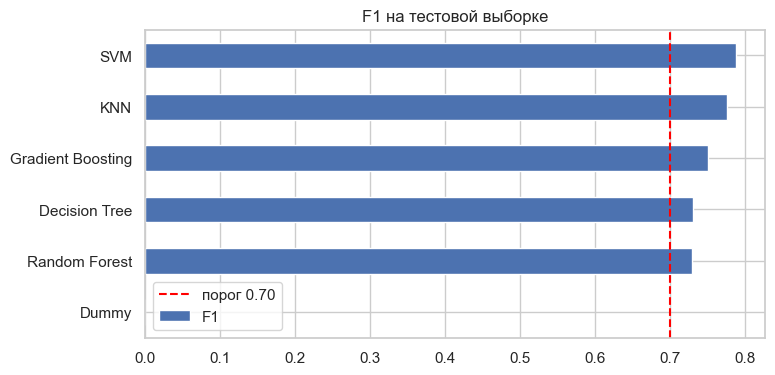

,F1 train,F1 test,train - test
Dummy,0.0000,0.0000,0.0000
Decision Tree,0.7992,0.7302,0.0691
Random Forest,0.7797,0.7287,0.0510
Gradient Boosting,0.9143,0.7500,0.1643
SVM,0.7784,0.7879,-0.0095
KNN,0.8387,0.7761,0.0626


In [ ]:
gap = pd.DataFrame({"F1 train": pd.Series({n: f1_score(y_tr, m.predict(X_tr)) for n, m in fitted.items()}),
                    "F1 test": summary["F1"]})
gap["train - test"] = gap["F1 train"] - gap["F1 test"]

ax = summary["F1"].sort_values().plot(kind="barh", figsize=(8, 4), color="#4c72b0", title="F1 на тестовой выборке")
ax.axvline(MIN_F1, color="red", linestyle="--", label="порог 0.70")
ax.legend()
plt.show()
gap.round(4)

- Условия для всех моделей одинаковы: общее разбиение, общая предобработка (единственное отличие — `StandardScaler` у SVM и KNN) и подбор гиперпараметров на одних и тех же фолдах обучающей выборки.
- **Порог F1 > 0.70 преодолели все пять моделей**, baseline его не достиг.
- **Порядок по F1 на test:** SVM (0.788) → KNN (0.776) → Gradient Boosting (0.750) → Decision Tree (0.730) → Random Forest (0.729).
- **Возможные причины различий:**
  - выборка небольшая (712 объектов в train), признаков мало, а основной сигнал сосредоточен в двух-трёх из них (пол/обращение, класс). Граница между классами получается простой, поэтому SVM и KNN на стандартизованных признаках с гладкой границей справляются лучше деревьев со ступенчатыми разбиениями;
  - глубина DT и RF ограничена ради борьбы с переобучением, что снижает их Recall — часть выживших мужчин пропускается;
  - Gradient Boosting сильнее остальных подгоняется под обучающие данные (разрыв F1 ≈ 0.16), поэтому его выигрыш над лесом на тесте скромный;
  - в тесте всего 179 объектов: одна ошибка сдвигает F1 примерно на 0.01, и порядок близких по качеству моделей отчасти случаен.
- У всех моделей Recall ниже Precision: преобладающий класс «погиб» делает ошибки FN более частыми, чем FP.

## 7. Важность признаков

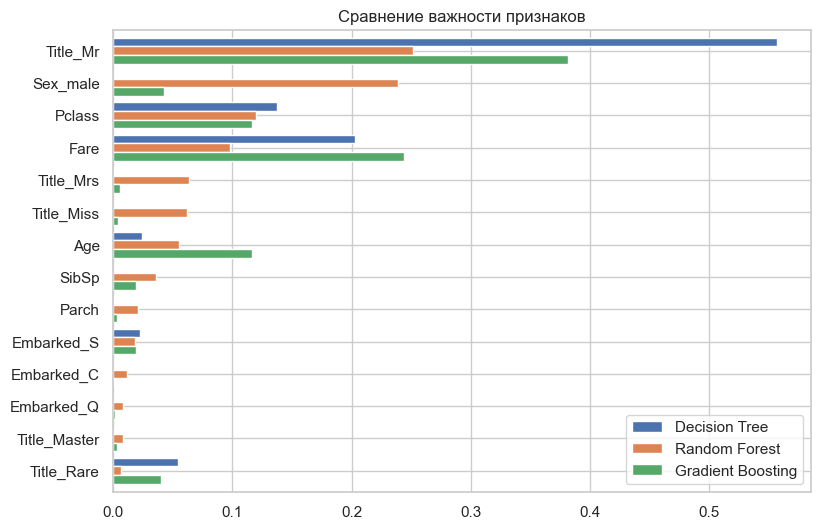

,Decision Tree,Random Forest,Gradient Boosting
Title_Mr,0.557,0.251,0.382
Sex_male,0.000,0.239,0.042
Pclass,0.138,0.120,0.117
Fare,0.203,0.098,0.244
Title_Mrs,0.001,0.064,0.006
Title_Miss,0.000,0.062,0.004
Age,0.024,0.056,0.117
SibSp,0.000,0.036,0.020
Parch,0.001,0.021,0.003
Embarked_S,0.022,0.018,0.019


In [26]:
fi_all = pd.DataFrame({"Decision Tree": fi_tree, "Random Forest": fi_forest, "Gradient Boosting": fi_boost})
fi_all = fi_all.sort_values("Random Forest", ascending=False)

fi_all.plot(kind="barh", figsize=(9, 6), width=0.8)
plt.gca().invert_yaxis()
plt.title("Сравнение важности признаков")
plt.show()
fi_all.round(3)

- **Лидеры у всех трёх моделей:** `Title_Mr`, `Sex_male`, `Pclass`, `Fare`, затем `Age`. Вклад `Embarked`, `SibSp`, `Parch` минимален.
- **Различия между моделями:** все три ставят на первое место `Title_Mr`. Дерево и бустинг почти не обращаются к `Sex_male`, так как он дублирует `Title_Mr`; случайный лес делит вес между ними практически поровну. Конкретные значения зависят от алгоритма, но состав главных факторов совпадает.
- **Согласованность с EDA:** там сильнее всего различалась выживаемость по полу/обращению (74% против 19%) и классу (63% против 24%), стоимость билета была связана с классом, а `Embarked`, `SibSp`, `Parch` показали слабую связь. Модели подтверждают эти наблюдения.

**Является ли важный признак причиной выживания? Нет.**
Важность признака отражает лишь его полезность для предсказания, то есть статистическую связь в этих данных. Высокая цена билета сама никого не спасала: `Fare` связан с классом, а класс — с расположением кают и доступом к шлюпкам. Пол важен благодаря правилу эвакуации «женщины и дети первыми». Кроме того, при коррелирующих признаках важность перераспределяется между ними (`Title_Mr` и `Sex_male`), а встроенная оценка завышает признаки с большим числом уникальных значений. Данные наблюдательные, и для выводов о причинности нужны эксперимент или специальные методы причинного анализа.

## 8. Разбор ошибок лучшей модели

лучшая модель по CV F1: SVM
{'верно': 151, 'FN': 17, 'FP': 11}


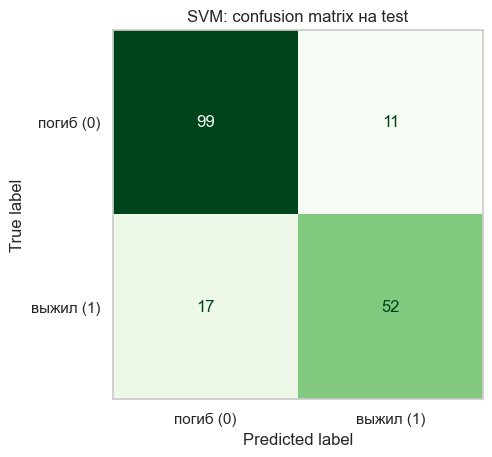

пропущено выживших (FN / все выжившие): 0.246
ложно «спасено» (FP / все погибшие): 0.1
          n  доля выживших  FP  FN  доля ошибок
Sex                                            
female   61           0.74  10   0         0.16
male    118           0.20   1  17         0.15 

          n  доля выживших  FP  FN  доля ошибок
Pclass                                         
1        45           0.56   2   9         0.24
2        34           0.59   1   2         0.09
3       100           0.24   8   6         0.14 

          n  доля выживших  FP  FN  доля ошибок
Title                                          
Master    9           0.67   0   0         0.00
Miss     41           0.68   7   0         0.17
Mr      105           0.17   0  17         0.16
Mrs      19           0.84   3   0         0.16
Rare      5           0.20   1   0         0.20 

             n  доля выживших  FP  FN  доля ошибок
age_group                                         
0-12        14           0.50   1   0

In [27]:
# лучшая модель определяется по F1 на кросс-валидации (train), а не по тесту
top_name = summary.drop("Dummy")["CV F1"].astype(float).idxmax()
top = fitted[top_name]
print("лучшая модель по CV F1:", top_name)

te = df.loc[X_te.index].copy()
te["pred"] = top.predict(X_te)
te["error"] = np.select([te["pred"] == te["Survived"], te["pred"] == 1], ["верно", "FP"], "FN")
print(te["error"].value_counts().to_dict())

cm = confusion_matrix(y_te, te["pred"])
ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Greens", colorbar=False)
plt.title(f"{top_name}: confusion matrix на test")
plt.grid(False)
plt.show()
print("пропущено выживших (FN / все выжившие):", round(cm[1, 0] / cm[1].sum(), 3))
print("ложно «спасено» (FP / все погибшие):", round(cm[0, 1] / cm[0].sum(), 3))

te["age_group"] = pd.cut(te["Age"], [0, 12, 18, 40, 60, 100], labels=["0-12", "13-18", "19-40", "41-60", "60+"])
te["age_group"] = te["age_group"].cat.add_categories("нет данных").fillna("нет данных")

def error_table(col):
    g = te.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(),
                         "доля выживших": g["Survived"].mean(),
                         "FP": g["error"].apply(lambda e: (e == "FP").sum()),
                         "FN": g["error"].apply(lambda e: (e == "FN").sum()),
                         "доля ошибок": g["error"].apply(lambda e: (e != "верно").mean())}).round(2)

for col in ["Sex", "Pclass", "Title", "age_group"]:
    print(error_table(col), "\n")

Лучшей по кросс-валидации оказалась **SVM** (CV F1 = 0.772); на тесте она тоже показала лучший F1.
- Правильно классифицированы 151 из 179 пассажиров. **FN (17) встречаются чаще, чем FP (11):** модель пропустила 25% реально выживших из 69, а из 110 погибших ошибочно «спасла» 10%.
- **Пол.** У мужчин почти все ошибки — FN (17 из 18), у женщин — только FP (10 из 10). Фактически модель усвоила правило «женщина или ребёнок — выжил, взрослый мужчина — погиб» и промахивается на исключениях: выживших мужчинах `Mr` и погибших женщинах.
- **Класс.** Больше всего ошибок в 1-м классе (24%, преимущественно FN — выжившие мужчины) и 3-м классе (8 FP — погибшие женщины).
- **Возраст.** Чаще всего ошибки в группе 19–40 лет (20%); у детей и пассажиров с обращением `Master` их практически нет.

In [28]:
show_cols = ["Name", "Sex", "Age", "Pclass", "Title", "SibSp", "Parch", "Fare", "Embarked", "Survived", "pred"]
print("Примеры False Positive:")
display(te[te["error"] == "FP"][show_cols].head(5))
print("Примеры False Negative:")
display(te[te["error"] == "FN"][show_cols].head(5))
print("Доля выживших среди женщин по классам (весь датасет):")
df[df["Sex"] == "female"].groupby("Pclass")["Survived"].mean().round(2)

Примеры False Positive:


,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,Survived,pred
297,"Allison, Miss. Helen Loraine",female,2.0,1,Miss,1,2,151.5500,S,0,1
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,Mrs,1,0,9.4750,S,0,1
564,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,Miss,0,0,8.0500,S,0,1
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,Miss,0,0,7.6292,Q,0,1
578,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,3,Mrs,1,0,14.4583,C,0,1


Примеры False Negative:


,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,Survived,pred
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,0,0,7.2250,C,1,0
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,Mr,1,0,52.0000,S,1,0
455,"Jalsevac, Mr. Ivan",male,29.0,3,Mr,0,0,7.8958,C,1,0
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,0,0,13.0000,S,1,0
701,"Silverthorne, Mr. Spencer Victor",male,35.0,1,Mr,0,0,26.2875,S,1,0


Доля выживших среди женщин по классам (весь датасет):


Pclass
1    0.97
2    0.92
3    0.50
Name: Survived, dtype: float64

**Почему модель ошибается на конкретных примерах**
- **FP — женщины 3-го класса** (Ahlin, Meanwell, O'Sullivan, Caram и др.). Среди женщин 1–2 классов выжили 92–97%, а в 3-м классе — лишь половина. Модель руководствуется полом и обращением и предсказывает спасение, но для 3-го класса это почти бросок монеты.
- **FP — Helen Allison** (2 года, 1-й класс). По признакам это ребёнок из 1-го класса, которому следовало выжить, однако она единственная погибшая девочка младше 12 лет из 1-го класса. Такой исход по имеющимся признакам предсказать невозможно.
- **FN — мужчины `Mr`** (Leeni, Taylor, Jalsevac, Williams, Silverthorne). По данным они не отличаются от погибших мужчин того же класса и возраста; их спасение определялось факторами вне датасета — местом на судне в момент катастрофы, случайностью. У Williams возраст отсутствует и заменён медианой.

### Проверка на идентифицирующие признаки и утечку информации

In [29]:
print("признаки на входе классификатора:", [n.split("__")[1] for n in top.named_steps["prep"].get_feature_names_out()])
for col in ["PassengerId", "Name", "Ticket", "Cabin"]:
    print(f"{col:12s} используется: {col in ALL_COLS}")
print()
print("число уникальных значений в train:", X_tr.nunique().to_dict())
print("F1 train:", round(f1_score(y_tr, top.predict(X_tr)), 4), "| F1 test:", round(scores[top_name]["F1"], 4))

признаки на входе классификатора: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
PassengerId  используется: False
Name         используется: False
Ticket       используется: False
Cabin        используется: False

число уникальных значений в train: {'Pclass': 3, 'Age': 85, 'SibSp': 7, 'Parch': 7, 'Fare': 226, 'Sex': 2, 'Embarked': 3, 'Title': 5}
F1 train: 0.7784 | F1 test: 0.7879


- `PassengerId`, `Name`, `Ticket`, `Cabin` в модель не попали. Использованные признаки описывают пассажира, но не позволяют однозначно его определить: у категориальных от 2 до 5 значений, а `Age` и `Fare` повторяются у многих людей. `Title` получен из имени, но содержит всего пять обобщённых категорий.
- Признаков, которые становятся известны лишь после катастрофы, в данных нет; все преобразования обучались только на train.
- F1 на train (0.778) и test (0.788) практически равны — запоминания пассажиров нет (для контраста: дерево на `PassengerId` — 1.0 на train и около 0.4 на test).
- **Вывод:** высокое качество модели не объясняется ни идентифицирующими признаками, ни утечкой информации.

## Общие выводы
- Идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`) исключены; из имени выделено обращение `Title`. Пропуски в `Age` заполнены медианой, в `Embarked` — модой, категории закодированы One-Hot; вся обработка в `Pipeline` и обучается только на train.
- Baseline (Dummy): Accuracy ≈ 0.61, F1 = 0. **Порог F1 > 0.70 преодолели все пять моделей:** SVM — 0.788, KNN — 0.776, Gradient Boosting — 0.750, Decision Tree — 0.730, Random Forest — 0.729.
- **Лучшая модель — SVM (RBF):** F1 = 0.788, Accuracy = 0.844, Precision = 0.825, Recall = 0.754; выбрана по кросс-валидации на обучающей выборке.
- Наибольшее влияние на предсказание оказывают пол/обращение, класс, стоимость билета и возраст. Это статистическая связь, а не причина выживания.
- Масштабирование критично для SVM (F1 по CV 0.44 → 0.75) и KNN (0.60 → 0.74) и не нужно деревьям.
- Дерево без ограничений сильно переобучается; ограничение глубины и ансамбли смягчают проблему, а у бустинга разрыв train/test остаётся самым большим.
- Ошибки модели — это исключения из правила «женщины и дети первыми»: пропущенные выжившие мужчины (FN) и погибшие женщины 3-го класса (FP). Утечки информации и запоминания конкретных пассажиров нет.